In [2]:
%pip install yfinance pandas numpy matplotlib statsmodels

Note: you may need to restart the kernel to use updated packages.


In [3]:

# Step 1: Download Maybank Stock Data

import yfinance as yf
import pandas as pd

# Download historical Maybank stock data
maybank = yf.download(
    "1155.KL",
    start="2021-01-01",
    end="2026-11-21",
    auto_adjust=False,
    progress=False
)

# Check if data was downloaded
if maybank.empty:
    raise ValueError("No data downloaded. Check your internet connection.")

# Fix column names if needed
if isinstance(maybank.columns, pd.MultiIndex):
    maybank.columns = maybank.columns.get_level_values(0)

# Display first five rows
print("Total records:", len(maybank))
display(maybank.head())


Total records: 1440


Price,Adj Close,Close,High,Low,Open,Volume
Date,,,,,,
2021-01-04,5.632041,8.35,8.48,8.33,8.47,4278900
2021-01-05,5.605062,8.31,8.36,8.21,8.34,5386900
2021-01-06,5.557847,8.24,8.35,8.20,8.31,4014500
2021-01-07,5.584826,8.28,8.28,8.04,8.20,13503300
2021-01-08,5.665766,8.40,8.40,8.10,8.24,9074600


In [4]:

# Save Maybank data in the new project folder

import os

# Create a data folder
os.makedirs("data", exist_ok=True)

# Save as CSV
maybank.to_csv("data/maybank.csv")

print("Maybank data saved successfully!")


Maybank data saved successfully!


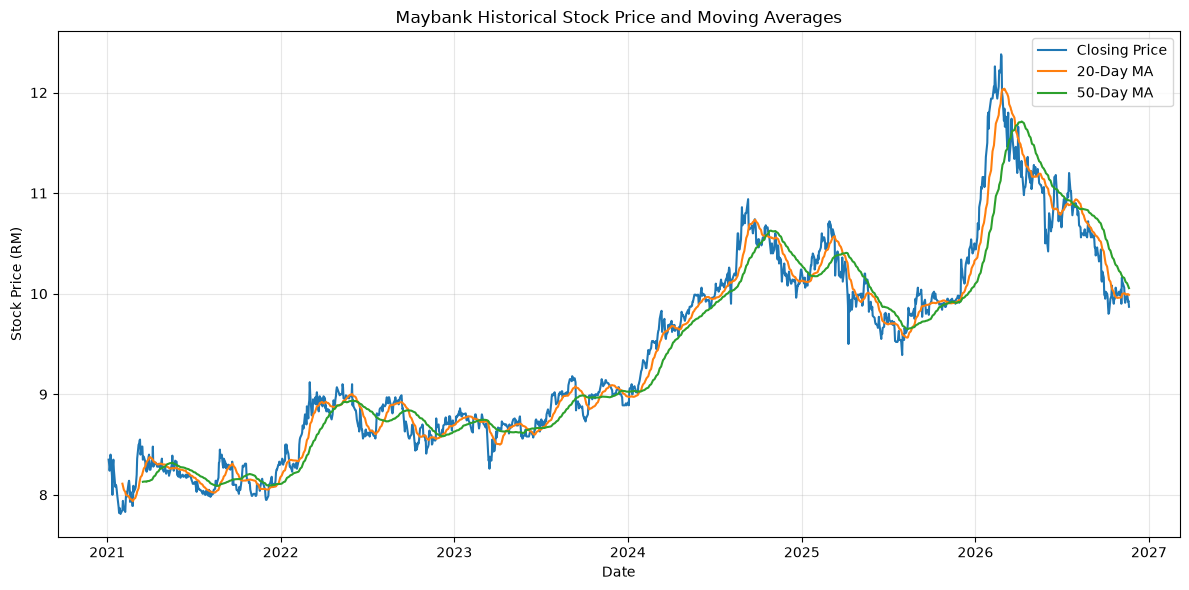

In [5]:

# Step 2: Historical Stock Price and Moving Averages

import pandas as pd
import matplotlib.pyplot as plt
import os

# Load saved Maybank data
df = pd.read_csv("data/maybank.csv")

# Convert Date column
df["Date"] = pd.to_datetime(df["Date"])

# Arrange data from oldest to newest
df = df.sort_values("Date")

# Remove missing closing prices
df = df.dropna(subset=["Close"]).copy()

# Calculate moving averages
df["MA20"] = df["Close"].rolling(window=20).mean()
df["MA50"] = df["Close"].rolling(window=50).mean()

# Create chart
plt.figure(figsize=(12, 6))

plt.plot(df["Date"], df["Close"], label="Closing Price")
plt.plot(df["Date"], df["MA20"], label="20-Day MA")
plt.plot(df["Date"], df["MA50"], label="50-Day MA")

plt.title("Maybank Historical Stock Price and Moving Averages")
plt.xlabel("Date")
plt.ylabel("Stock Price (RM)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

# Save chart
os.makedirs("outputs", exist_ok=True)
plt.savefig("outputs/maybank_price_trend.png", dpi=300)

plt.show()


In [6]:

# Step 3: Stationarity Testing

import numpy as np
from statsmodels.tsa.stattools import adfuller

# Calculate log closing prices
df["log_close"] = np.log(df["Close"])

# Calculate first difference
df["log_diff"] = df["log_close"].diff()

# Perform ADF tests
adf_price = adfuller(df["log_close"].dropna())
adf_diff = adfuller(df["log_diff"].dropna())

# Display results
print("Log Price p-value:", round(adf_price[1], 6))
print("First Difference p-value:", round(adf_diff[1], 6))


Log Price p-value: 0.595432
First Difference p-value: 0.0


In [7]:

# Step 4: Build ARIMA Model

import numpy as np
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller

# Split data into 90% training and 10% testing
split = int(len(df) * 0.9)

train = df.iloc[:split]
test = df.iloc[split:]

# Use log closing prices for forecasting
train_log = np.log(train["Close"])

# Check stationarity using training data only
p_level = adfuller(train_log)[1]
p_diff = adfuller(train_log.diff().dropna())[1]

# Select differencing order
if p_level < 0.05:
    d = 0
elif p_diff < 0.05:
    d = 1
else:
    raise ValueError("Stationarity needs further investigation.")

# Fit ARIMA model
order = (1, d, 1)
model = ARIMA(train_log, order=order)
fitted_model = model.fit()

# Display results
print("Training records:", len(train))
print("Testing records:", len(test))
print("ARIMA Model:", order)
print("AIC:", round(fitted_model.aic, 2))
print("Converged:", fitted_model.mle_retvals.get("converged"))


Training records: 1296
Testing records: 144
ARIMA Model: (1, 1, 1)
AIC: -8884.61
Converged: True


ARIMA RMSE: RM 0.862
Random Walk RMSE: RM 0.8924


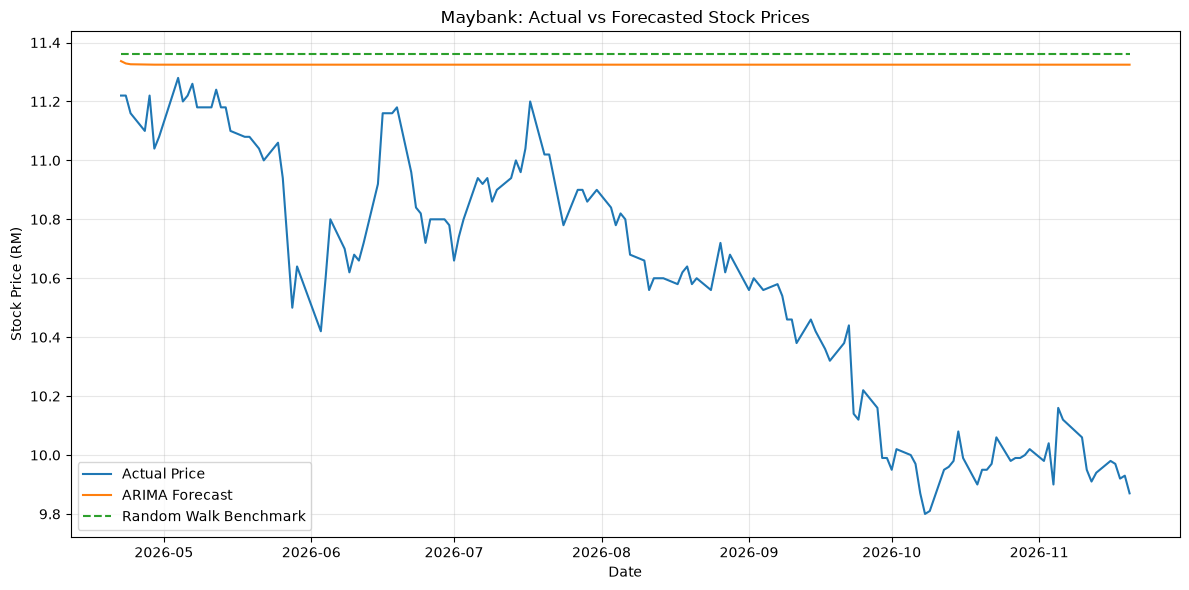

In [8]:

# Step 5: ARIMA Forecasting and Model Evaluation

import numpy as np
import matplotlib.pyplot as plt

# 1. Forecast the testing period
forecast_log = fitted_model.forecast(steps=len(test))

# Convert log prices back to RM
forecast_price = np.exp(np.asarray(forecast_log))

# 2. Get actual stock prices
actual_price = test["Close"].to_numpy()

# 3. Simple benchmark: last training price
last_price = train["Close"].iloc[-1]
naive_forecast = np.full(len(test), last_price)

# 4. Calculate RMSE
arima_rmse = np.sqrt(np.mean(
    (actual_price - forecast_price) ** 2
))

naive_rmse = np.sqrt(np.mean(
    (actual_price - naive_forecast) ** 2
))

print("ARIMA RMSE: RM", round(arima_rmse, 4))
print("Random Walk RMSE: RM", round(naive_rmse, 4))

# 5. Plot actual vs forecasted prices
plt.figure(figsize=(12, 6))

plt.plot(test["Date"], actual_price, label="Actual Price")
plt.plot(test["Date"], forecast_price, label="ARIMA Forecast")
plt.plot(test["Date"], naive_forecast, "--",
         label="Random Walk Benchmark")

plt.title("Maybank: Actual vs Forecasted Stock Prices")
plt.xlabel("Date")
plt.ylabel("Stock Price (RM)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("outputs/maybank_arima_forecast.png", dpi=300)
plt.show()


In [9]:

# Step 6: Financial Risk Analysis

import numpy as np

# Calculate daily returns using adjusted closing prices
df["Daily_Return"] = df["Adj Close"].pct_change()

returns = df["Daily_Return"].dropna()

# 1. Annualised volatility
volatility = returns.std() * np.sqrt(252)

# 2. Historical Value-at-Risk (95% confidence)
var_95 = -np.percentile(returns, 5)

# 3. Conditional Value-at-Risk
cvar_95 = -returns[returns <= -var_95].mean()

# Display results
print("Annualised Volatility:", round(volatility * 100, 2), "%")
print("95% Daily VaR:", round(var_95 * 100, 2), "%")
print("95% Daily CVaR:", round(cvar_95 * 100, 2), "%")


Annualised Volatility: 12.33 %
95% Daily VaR: 1.12 %
95% Daily CVaR: 1.73 %


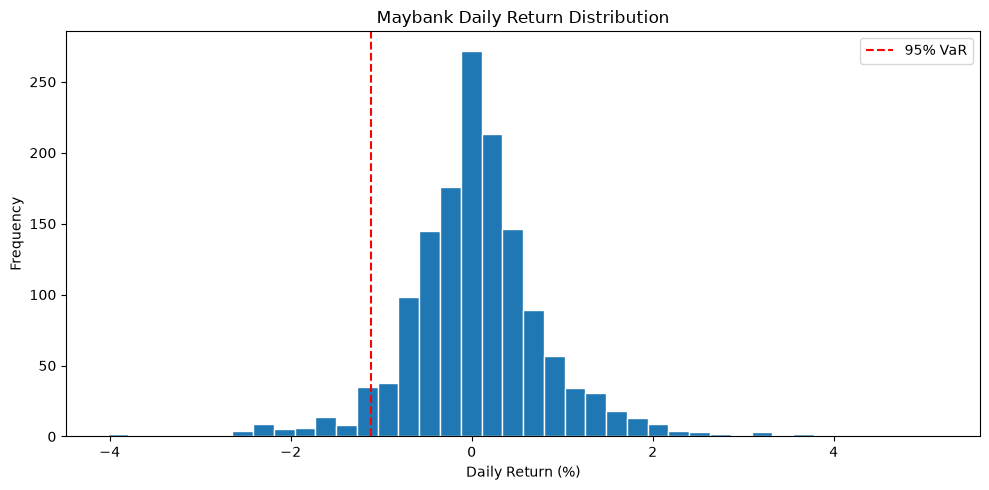

In [10]:

# Daily Return Distribution

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(returns * 100, bins=40, edgecolor="white")

# Mark the historical VaR threshold
plt.axvline(
    -var_95 * 100,
    color="red",
    linestyle="--",
    label="95% VaR"
)

plt.title("Maybank Daily Return Distribution")
plt.xlabel("Daily Return (%)")
plt.ylabel("Frequency")
plt.legend()
plt.tight_layout()

plt.savefig("outputs/maybank_risk_distribution.png", dpi=300)
plt.show()


Starting Price: RM 9.87
5th Percentile: RM 9.32
Median Price: RM 9.96
95th Percentile: RM 10.69


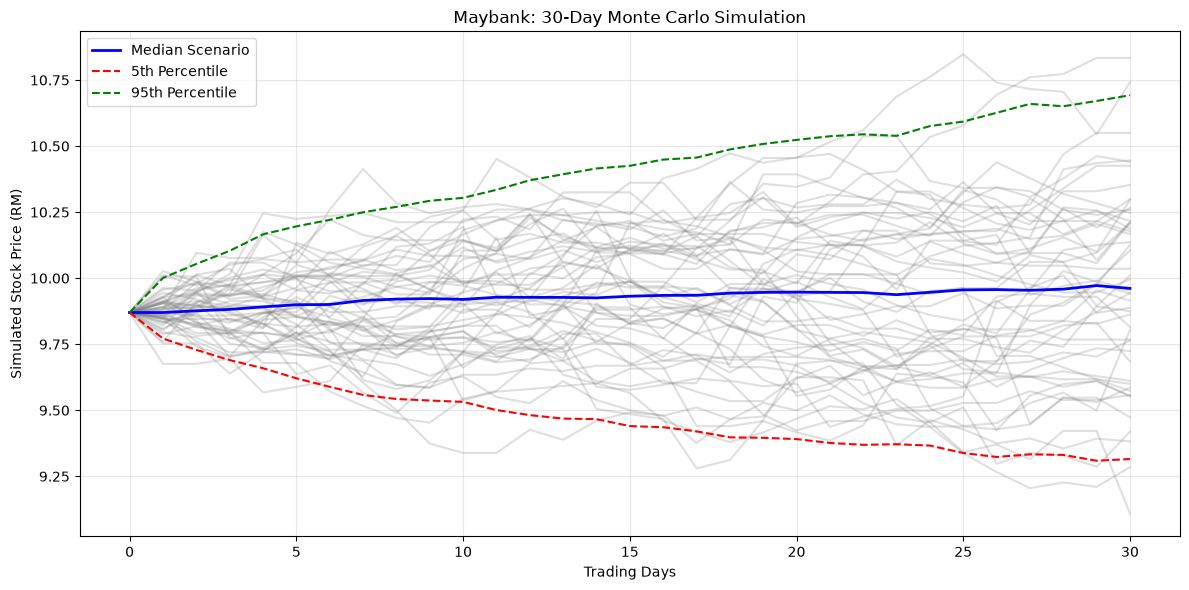

In [11]:

# Step 7: Monte Carlo Simulation

import numpy as np
import matplotlib.pyplot as plt

# 1. Prepare adjusted closing prices
prices = df["Adj Close"].dropna()

# Calculate historical daily log returns
log_returns = np.log(prices / prices.shift(1)).dropna()

# 2. Set simulation parameters
days = 30
simulations = 1000
start_price = prices.iloc[-1]

# 3. Randomly sample historical returns
rng = np.random.default_rng(42)

random_returns = rng.choice(
    log_returns,
    size=(days, simulations),
    replace=True
)

# 4. Calculate simulated stock prices
simulated_prices = start_price * np.exp(
    np.cumsum(random_returns, axis=0)
)

# Include the starting price (Day 0)
paths = np.vstack([
    np.full(simulations, start_price),
    simulated_prices
])

# 5. Calculate ending price scenarios
final_prices = paths[-1]

lower = np.percentile(final_prices, 5)
median = np.median(final_prices)
upper = np.percentile(final_prices, 95)

print("Starting Price: RM", round(start_price, 2))
print("5th Percentile: RM", round(lower, 2))
print("Median Price: RM", round(median, 2))
print("95th Percentile: RM", round(upper, 2))

# 6. Visualise 50 simulated paths
plt.figure(figsize=(12, 6))

plt.plot(paths[:, :50], color="gray", alpha=0.25)

plt.plot(
    np.median(paths, axis=1),
    color="blue",
    linewidth=2,
    label="Median Scenario"
)

plt.plot(
    np.percentile(paths, 5, axis=1),
    color="red",
    linestyle="--",
    label="5th Percentile"
)

plt.plot(
    np.percentile(paths, 95, axis=1),
    color="green",
    linestyle="--",
    label="95th Percentile"
)

plt.title("Maybank: 30-Day Monte Carlo Simulation")
plt.xlabel("Trading Days")
plt.ylabel("Simulated Stock Price (RM)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("outputs/maybank_monte_carlo.png", dpi=300)
plt.show()


Last Actual Price: RM 9.87
Day 1 Forecast: RM 9.88
Day 30 Forecast: RM 9.89


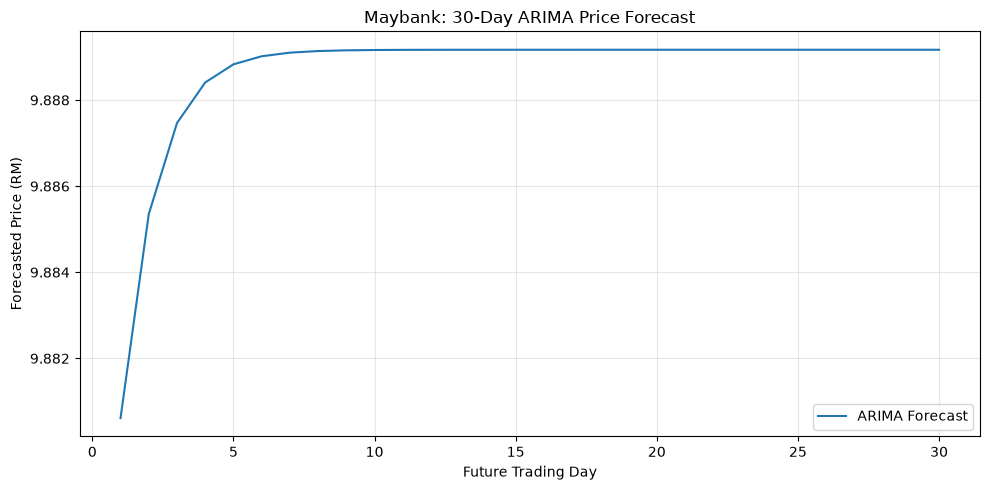

In [12]:

# Step 8: Future Stock Price Forecasting

from statsmodels.tsa.arima.model import ARIMA
import numpy as np
import matplotlib.pyplot as plt

# 1. Use all historical closing prices
full_log = np.log(df["Close"])

# 2. Train ARIMA using all available data
final_model = ARIMA(full_log, order=order).fit()

# 3. Forecast the next 30 trading observations
future_log = final_model.forecast(steps=30)
future_prices = np.exp(np.asarray(future_log))

# 4. Display results
print("Last Actual Price: RM", round(df["Close"].iloc[-1], 2))
print("Day 1 Forecast: RM", round(future_prices[0], 2))
print("Day 30 Forecast: RM", round(future_prices[-1], 2))

# 5. Plot future forecasts
plt.figure(figsize=(10, 5))

plt.plot(range(1, 31), future_prices,
         label="ARIMA Forecast")

plt.title("Maybank: 30-Day ARIMA Price Forecast")
plt.xlabel("Future Trading Day")
plt.ylabel("Forecasted Price (RM)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("outputs/maybank_future_forecast.png", dpi=300)
plt.show()


Last Actual Price: RM 9.87
Day 30 Forecast: RM 9.89
95% Lower Limit: RM 9.28
95% Upper Limit: RM 10.54


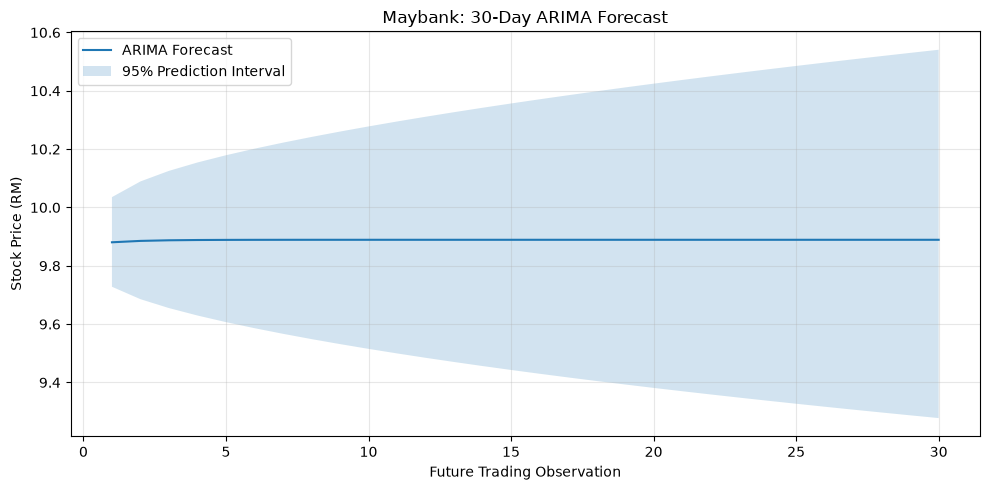

In [13]:

# Step 8: Future ARIMA Forecast with Prediction Interval

# Train model using all historical prices
final_model = ARIMA(
    np.log(df["Close"]), order=order
).fit()

# Forecast next 30 trading observations
forecast = final_model.get_forecast(steps=30)

# Convert log forecasts to price (RM)
future_prices = np.exp(forecast.predicted_mean)
interval = np.exp(forecast.conf_int())

lower = interval.iloc[:, 0]
upper = interval.iloc[:, 1]

# Display results
print("Last Actual Price: RM", round(df["Close"].iloc[-1], 2))
print("Day 30 Forecast: RM", round(future_prices.iloc[-1], 2))
print("95% Lower Limit: RM", round(lower.iloc[-1], 2))
print("95% Upper Limit: RM", round(upper.iloc[-1], 2))

# Plot forecast
days = range(1, 31)

plt.figure(figsize=(10, 5))

plt.plot(days, future_prices, label="ARIMA Forecast")

plt.fill_between(
    days, lower, upper,
    alpha=0.2, label="95% Prediction Interval"
)

plt.title("Maybank: 30-Day ARIMA Forecast")
plt.xlabel("Future Trading Observation")
plt.ylabel("Stock Price (RM)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("outputs/maybank_future_forecast.png", dpi=300)
plt.show()
